In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("House_Rent_Dataset.csv")

In [4]:
df.head(5)

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Posted On          4746 non-null   str  
 1   BHK                4746 non-null   int64
 2   Rent               4746 non-null   int64
 3   Size               4746 non-null   int64
 4   Floor              4746 non-null   str  
 5   Area Type          4746 non-null   str  
 6   Area Locality      4746 non-null   str  
 7   City               4746 non-null   str  
 8   Furnishing Status  4746 non-null   str  
 9   Tenant Preferred   4746 non-null   str  
 10  Bathroom           4746 non-null   int64
 11  Point of Contact   4746 non-null   str  
dtypes: int64(4), str(8)
memory usage: 887.8 KB


In [7]:
df.isnull().sum()

Posted On            0
BHK                  0
Rent                 0
Size                 0
Floor                0
Area Type            0
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             0
Point of Contact     0
dtype: int64

In [9]:
df['City'].value_counts()

City
Mumbai       972
Chennai      891
Bangalore    886
Hyderabad    868
Delhi        605
Kolkata      524
Name: count, dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.shape

(4746, 12)

In [12]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='str')

21.409942283288803


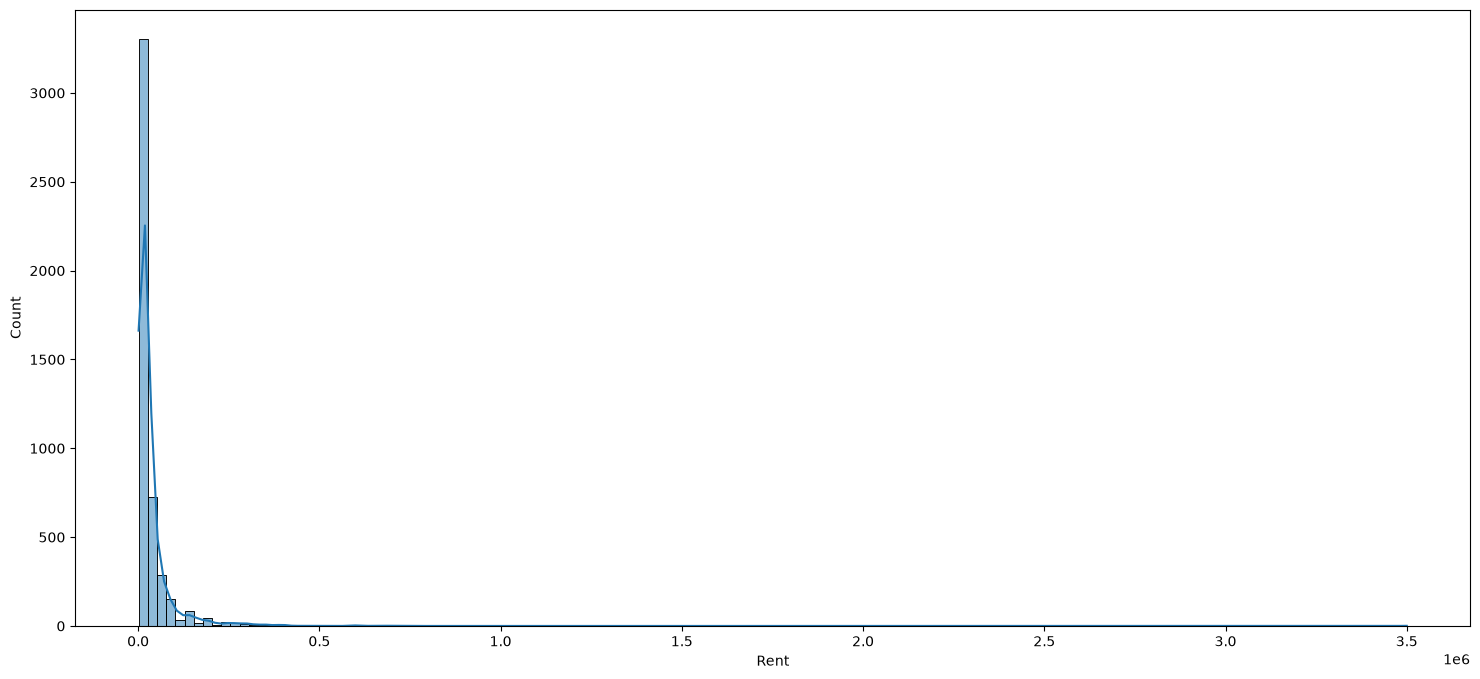

In [6]:
import matplotlib.pyplot as plt

print(df["Rent"].skew())

plt.figure(figsize=(18, 8))
sns.histplot(x=df["Rent"], kde=True)

plt.show()

In [13]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.746000e+03,4746.000000,4746.000000
mean,2.083860,3.499345e+04,967.490729,1.965866
std,0.832256,7.810641e+04,634.202328,0.884532
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [14]:
df['Furnishing Status'].value_counts()

Furnishing Status
Semi-Furnished    2251
Unfurnished       1815
Furnished          680
Name: count, dtype: int64

In [15]:
df['Tenant Preferred'].value_counts()

Tenant Preferred
Bachelors/Family    3444
Bachelors            830
Family               472
Name: count, dtype: int64

In [18]:
df['Bathroom'].value_counts()

Bathroom
2     2291
1     1474
3      749
4      156
5       60
6       12
7        3
10       1
Name: count, dtype: int64

In [19]:
df['Point of Contact'].value_counts()

Point of Contact
Contact Owner      3216
Contact Agent      1529
Contact Builder       1
Name: count, dtype: int64

In [29]:
df = df.drop(columns=["Posted On"])


In [56]:
df["Rent_log"] = np.log1p(df["Rent"]) #outliner yaptım


In [25]:
from sklearn.preprocessing import LabelEncoder


In [35]:
label_encoder = LabelEncoder()

columns_to = ['Point of Contact' , 'Tenant Preferred' , 'Furnishing Status' , 'City' , 'Area Type' , 'Area Locality' , 'Floor']


for col in columns_to:
    df[col] = label_encoder.fit_transform(df[col])
    

In [57]:
df.sample(5)

,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_log
2574,3,70000,1800,458,1,1077,2,1,1,3,0,11.156265
1254,3,45000,850,349,1,1297,5,2,2,3,0,10.714440
2647,2,10000,70,16,2,1821,2,1,1,2,2,9.210440
3721,3,23000,1000,14,1,976,1,2,0,3,2,10.043293
4168,2,17500,1400,315,2,1270,3,0,1,2,2,9.770013


In [58]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score
from sklearn.ensemble import RandomForestRegressor


x = df.drop(columns = ['Rent' , 'Rent_log'])
y = df['Rent_log']

In [59]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [60]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train , y_train)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](10,)","[ 0.13, 0. ,-0. ,...,-0. , 0.33,-0.35]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['BHK','Size','Floor',...,'Tenant Preferred','Bathroom','Point of Contact']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.338
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(10)


In [61]:
y_pred = lr.predict(x_test)
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test ,y_pred)


print(r2)
print(mse)

0.7329596825945774
0.23029685515859485


In [62]:
model = RandomForestRegressor()
model.fit(x_train , y_train)

y_pred1 = model.predict(x_test)
r2_rf = r2_score(y_test , y_pred1)
mse_rf = mean_squared_error(y_test ,y_pred1)


print(r2_rf)
print(mse_rf)

0.8333446900804256
0.1437243414884422


In [63]:
from xgboost import XGBRegressor

model1 = XGBRegressor(random_state = 42)
model1.fit(x_train , y_train)

y_pred2 = model1.predict(x_test)

r2_xb = r2_score(y_test , y_pred2)
mse_xb = mean_squared_error(y_test, y_pred2)


print(r2_xb)
print(mse_xb)

0.8240458929772045
0.1517436688710503


In [64]:
from sklearn.model_selection import cross_val_score

# 5-Fold Cross Validation using R2 score
cv_scores = cross_val_score(model, x, y, cv=5, scoring='r2')

print("Cross-Validation R2 Scores:", cv_scores)
print("Mean CV R2 Score:", cv_scores.mean())

Cross-Validation R2 Scores: [0.82333378 0.85438737 0.68745561 0.69053318 0.34210673]
Mean CV R2 Score: 0.6795633327402213
